### Production des Stats 


#### Imports

In [1]:
import geopandas as gpd
import json
from shapely.geometry import shape
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#### Import et assignation de chaque arret à un bassin

In [2]:
df_bassin = pd.read_csv("data/bassins-demploi-ile-de-france-2021.csv",sep=";")
df_hebdo = pd.read_csv(
    "data/offre_hebdomadaire_moyenne_hors_vacances.csv",
    sep=";"
)

C:\Users\0504686X\AppData\Local\Temp\ipykernel_28324\1926041213.py:2: DtypeWarning: Columns (3: nom_ligne_commerciale) have mixed types. Specify dtype option on import or set low_memory=False.
  df_hebdo = pd.read_csv(


In [3]:
df_bassin_geo = df_bassin.copy()

df_bassin_geo["geometry"] = df_bassin_geo["Geo Shape"].apply(
    lambda x: shape(json.loads(x))
)

df_bassin_geo = gpd.GeoDataFrame(
    df_bassin_geo,
    geometry="geometry",
    crs="EPSG:4326"
)

In [4]:
arrets_geo = (
    df_hebdo[
        df_hebdo["longitude_arret"].notna() &
        df_hebdo["latitude_arret"].notna()
    ][
        [
            "id_arret",
            "nom_arret",
            "longitude_arret",
            "latitude_arret"
        ]
    ]
    .drop_duplicates(subset="id_arret")
)

arrets_geo = gpd.GeoDataFrame(
    arrets_geo,
    geometry=gpd.points_from_xy(
        arrets_geo["longitude_arret"],
        arrets_geo["latitude_arret"]
    ),
    crs="EPSG:4326"
)

In [5]:
arrets_bassins = gpd.sjoin(
    arrets_geo,
    df_bassin_geo[
        ["CODE_BE", "NOM", "NOM COMPLET", "geometry"]
    ],
    how="left",
    predicate="within"
)

In [6]:
ref_arrets_bassins = arrets_bassins[
    ["id_arret", "CODE_BE", "NOM", "NOM COMPLET"]
].copy()

df_hebdo_bassin = df_hebdo.merge(
    ref_arrets_bassins,
    on="id_arret",
    how="left"
)

#### Taux maintiens d'arrets

##### Taux maintiens arrets bassin

In [7]:
# Nombre d'arrêts desservis par bassin et par heure
couverture_bassin_heure = (
    df_hebdo_bassin[
        (df_hebdo_bassin["nb_courses_mardi"] > 0) &
        (df_hebdo_bassin["CODE_BE"].notna())
    ]
    .groupby(
        ["CODE_BE", "NOM COMPLET", "tranche_horaire"]
    )["id_arret"]
    .nunique()
    .reset_index(name="nb_arrets_desservis")
)


# Passage des heures en colonnes
comparaison_bassins = (
    couverture_bassin_heure
    .pivot(
        index=["CODE_BE", "NOM COMPLET"],
        columns="tranche_horaire",
        values="nb_arrets_desservis"
    )
    .fillna(0)
)


# Colonnes horaires souhaitées
comparaison_bassins["offre_23h"] = comparaison_bassins[23]
comparaison_bassins["offre_00h"] = comparaison_bassins[24]
comparaison_bassins["offre_01h"] = comparaison_bassins[25]
comparaison_bassins["offre_02h"] = comparaison_bassins[26]
comparaison_bassins["offre_03h"] = comparaison_bassins[27]
comparaison_bassins["offre_04h"] = comparaison_bassins[4]
comparaison_bassins["offre_05h"] = comparaison_bassins[5]

# On conserve ton indicateur de référence à 17h
comparaison_bassins["offre_17h"] = comparaison_bassins[17]


# Moyenne de la couverture horaire du bassin
# Calculée AVANT de sélectionner les colonnes finales
comparaison_bassins["offre_moyenne"] = (
    comparaison_bassins[
        list(range(4, 28))
    ].mean(axis=1)
)


# Taux de maintien de la couverture à 3h par rapport à 17h
comparaison_bassins["taux_maintien_3h_pct"] = (
    comparaison_bassins["offre_03h"]
    / comparaison_bassins["offre_17h"]
    * 100
).round(1)


# Tableau final
comparaison_bassins = (
    comparaison_bassins[
        [
            "offre_23h",
            "offre_00h",
            "offre_01h",
            "offre_02h",
            "offre_03h",
            "offre_04h",
            "offre_05h",
            "offre_17h",
            "offre_moyenne",
            "taux_maintien_3h_pct"
        ]
    ]
    .reset_index()
    .sort_values(
        "taux_maintien_3h_pct",
        ascending=False
    )
)

comparaison_bassins

tranche_horaire,CODE_BE,NOM COMPLET,offre_23h,offre_00h,offre_01h,offre_02h,offre_03h,offre_04h,offre_05h,offre_17h,offre_moyenne,taux_maintien_3h_pct
0,BE00002,Grand Roissy - Le Bourget,1450.0,1059.0,770.0,620.0,600.0,600.0,1574.0,2131.0,1682.166667,28.2
22,BE94T10,Paris Est Marne et Bois (EPT 10),687.0,681.0,484.0,207.0,187.0,287.0,683.0,838.0,718.083333,22.3
21,BE93T09,Grand Paris Grand Est (EPT 9),685.0,569.0,379.0,161.0,155.0,303.0,677.0,817.0,693.125000,19.0
20,BE93T08,Est Ensemble (EPT 8),682.0,663.0,357.0,153.0,146.0,94.0,643.0,773.0,650.000000,18.9
19,BE93T06,Plaine Commune (EPT 6),732.0,697.0,351.0,163.0,153.0,85.0,710.0,818.0,693.708333,18.7
8,BE75T01,Paris (T1),3145.0,3072.0,1746.0,623.0,621.0,243.0,1750.0,3360.0,2819.500000,18.5
16,BE92T02,Vallée Sud Grand Paris (EPT 2),612.0,578.0,396.0,175.0,175.0,39.0,602.0,981.0,741.666667,17.8
7,BE00T12,Grand-Orly Seine Bièvre (EPT 12),1261.0,1118.0,624.0,248.0,248.0,268.0,1234.0,1604.0,1281.458333,15.5
6,BE00T05,Boucle Nord de Seine (EPT 5),570.0,514.0,322.0,114.0,112.0,86.0,668.0,833.0,671.750000,13.4
17,BE92T03,Grand Paris Seine Ouest (EPT 3),380.0,372.0,194.0,83.0,73.0,30.0,338.0,648.0,499.541667,11.3


##### Taux de maintiens d'arrets par commune 

In [8]:
# --------------------------------------------------
# 1. Nombre d'arrêts desservis par commune et heure
# --------------------------------------------------

couverture_commune_heure = (
    df_hebdo[
        (df_hebdo["nb_courses_mardi"] > 0) &
        (df_hebdo["code_commune"].notna()) &
        (df_hebdo["nom_commune"].notna())
    ]
    .groupby(
        [
            "code_commune",
            "nom_commune",
            "tranche_horaire"
        ]
    )["id_arret"]
    .nunique()
    .reset_index(name="nb_arrets_desservis")
)


# --------------------------------------------------
# 2. Passage des heures en colonnes
# --------------------------------------------------

comparaison_communes = (
    couverture_commune_heure
    .pivot(
        index=[
            "code_commune",
            "nom_commune"
        ],
        columns="tranche_horaire",
        values="nb_arrets_desservis"
    )
    .fillna(0)
)


# --------------------------------------------------
# 3. Nombre d'arrêts desservis à 17h et 3h
# --------------------------------------------------

comparaison_communes["arrets_17h"] = comparaison_communes[17]
comparaison_communes["arrets_3h"] = comparaison_communes[27]


# --------------------------------------------------
# 4. Taux de maintien des arrêts
# --------------------------------------------------

comparaison_communes["taux_maintien_arrets_pct"] = (
    comparaison_communes["arrets_3h"]
    / comparaison_communes["arrets_17h"]
    * 100
).round(1)


# --------------------------------------------------
# 5. Éviter les divisions par zéro
# --------------------------------------------------

comparaison_communes.loc[
    comparaison_communes["arrets_17h"] == 0,
    "taux_maintien_arrets_pct"
] = None


# --------------------------------------------------
# 6. Tableau final
# --------------------------------------------------

comparaison_communes = (
    comparaison_communes[
        [
            "arrets_17h",
            "arrets_3h",
            "taux_maintien_arrets_pct"
        ]
    ]
    .reset_index()
)

comparaison_communes.columns.name = None


# --------------------------------------------------
# 7. Tri
# --------------------------------------------------

comparaison_communes = comparaison_communes.sort_values(
    "taux_maintien_arrets_pct",
    ascending=False
)

comparaison_communes

,code_commune,nom_commune,arrets_17h,arrets_3h,taux_maintien_arrets_pct
41,60142.0,La Chapelle-en-Serval,1.0,1.0,100.0
1315,95612.0,Le Thillay,14.0,12.0,85.7
394,77349.0,Othis,13.0,10.0,76.9
1311,95604.0,Survilliers,20.0,14.0,70.0
1090,93057.0,Les Pavillons-sous-Bois,39.0,23.0,59.0
...,...,...,...,...,...
834,89464.0,Villeneuve-sur-Yonne,0.0,0.0,NaN
889,91184.0,Courdimanche-sur-Essonne,0.0,0.0,NaN
1236,95304.0,Hédouville,0.0,0.0,NaN
1240,95313.0,L'Isle-Adam,0.0,2.0,NaN


In [9]:
comparaison_communes.to_csv(
    "taux_maintien_arrets_par_commune_mardi.csv",
    sep=";",
    index=False,
    encoding="utf-8-sig"
)

print("Export terminé : taux_maintien_arrets_par_commune_mardi.csv")

Export terminé : taux_maintien_arrets_par_commune_mardi.csv


#### Taux de maintiens de desserte 

##### Taux de maintiens de desserte par bassin

In [10]:
# Somme des dessertes par bassin et tranche horaire
dessertes_bassin_heure = (
    df_hebdo_bassin[
        df_hebdo_bassin["CODE_BE"].notna()
    ]
    .groupby(
        ["CODE_BE", "NOM COMPLET", "tranche_horaire"],
        as_index=False
    )
    .agg(
        nb_dessertes=("nb_courses_mardi", "sum")
    )
)


# Transformation : une ligne par bassin, une colonne par heure
dessertes_bassins = (
    dessertes_bassin_heure
    .pivot(
        index=["CODE_BE", "NOM COMPLET"],
        columns="tranche_horaire",
        values="nb_dessertes"
    )
    .fillna(0)
)


# Création des colonnes horaires lisibles
dessertes_bassins["dessertes_23h"] = dessertes_bassins[23]
dessertes_bassins["dessertes_00h"] = dessertes_bassins[24]
dessertes_bassins["dessertes_01h"] = dessertes_bassins[25]
dessertes_bassins["dessertes_02h"] = dessertes_bassins[26]
dessertes_bassins["dessertes_03h"] = dessertes_bassins[27]
dessertes_bassins["dessertes_04h"] = dessertes_bassins[4]
dessertes_bassins["dessertes_05h"] = dessertes_bassins[5]

# Heure de référence
dessertes_bassins["dessertes_17h"] = dessertes_bassins[17]


# Taux de maintien des dessertes entre 17h et 3h
dessertes_bassins["taux_maintien_dessertes_pct"] = (
    dessertes_bassins["dessertes_03h"]
    / dessertes_bassins["dessertes_17h"]
    * 100
).round(1)


# Conservation uniquement des colonnes utiles
dessertes_bassins = (
    dessertes_bassins[
        [
            "dessertes_23h",
            "dessertes_00h",
            "dessertes_01h",
            "dessertes_02h",
            "dessertes_03h",
            "dessertes_04h",
            "dessertes_05h",
            "dessertes_17h",
            "taux_maintien_dessertes_pct"
        ]
    ]
    .reset_index()
)

# Nettoyage de l'affichage
dessertes_bassins.columns.name = None


# Tri du bassin qui maintient le mieux son offre au moins bon
dessertes_bassins = dessertes_bassins.sort_values(
    "taux_maintien_dessertes_pct",
    ascending=False
)

dessertes_bassins

,CODE_BE,NOM COMPLET,dessertes_23h,dessertes_00h,dessertes_01h,dessertes_02h,dessertes_03h,dessertes_04h,dessertes_05h,dessertes_17h,taux_maintien_dessertes_pct
0,BE00002,Grand Roissy - Le Bourget,4806.485714,2882.428571,1562.657143,1071.400000,1340.314286,919.228571,5340.600000,14402.828571,9.3
20,BE93T08,Est Ensemble (EPT 8),2906.571429,2451.657143,862.714286,480.142857,459.714286,90.571429,2109.400000,7022.914286,6.5
8,BE75T01,Paris (T1),19904.514286,17301.257143,4461.942857,2450.914286,2438.428571,188.971429,4563.942857,45550.800000,5.4
19,BE93T06,Plaine Commune (EPT 6),2941.942857,2460.342857,683.542857,418.542857,404.285714,93.542857,2806.600000,7631.142857,5.3
21,BE93T09,Grand Paris Grand Est (EPT 9),2119.571429,1497.142857,692.714286,329.714286,332.714286,424.885714,2492.485714,6267.285714,5.3
7,BE00T12,Grand-Orly Seine Bièvre (EPT 12),4549.457143,3844.228571,1390.514286,676.685714,670.828571,302.914286,3917.200000,13003.828571,5.2
22,BE94T10,Paris Est Marne et Bois (EPT 10),2221.971429,2003.200000,924.200000,383.600000,358.114286,245.457143,1801.400000,7045.085714,5.1
16,BE92T02,Vallée Sud Grand Paris (EPT 2),2348.885714,2061.771429,868.800000,369.942857,368.942857,51.600000,1719.285714,7432.914286,5.0
6,BE00T05,Boucle Nord de Seine (EPT 5),1906.542857,1568.714286,588.428571,241.485714,233.828571,142.914286,2080.085714,7012.571429,3.3
17,BE92T03,Grand Paris Seine Ouest (EPT 3),1402.485714,1283.485714,379.428571,164.228571,163.600000,30.028571,860.600000,5528.742857,3.0


##### Taux maintiens de dessertes par commune 

In [11]:
# --------------------------------------------------
# 1. Nombre de dessertes par commune et par heure
# --------------------------------------------------

dessertes_commune_heure = (
    df_hebdo[
        (df_hebdo["code_commune"].notna()) &
        (df_hebdo["nom_commune"].notna())
    ]
    .groupby(
        [
            "code_commune",
            "nom_commune",
            "tranche_horaire"
        ],
        as_index=False
    )
    .agg(
        nb_dessertes=("nb_courses_mardi", "sum")
    )
)


# --------------------------------------------------
# 2. Passage des heures en colonnes
# --------------------------------------------------

dessertes_communes = (
    dessertes_commune_heure
    .pivot(
        index=[
            "code_commune",
            "nom_commune"
        ],
        columns="tranche_horaire",
        values="nb_dessertes"
    )
    .fillna(0)
)


# --------------------------------------------------
# 3. Dessertess à 17h et 3h
# --------------------------------------------------

dessertes_communes["dessertes_17h"] = dessertes_communes[17]
dessertes_communes["dessertes_3h"] = dessertes_communes[27]


# --------------------------------------------------
# 4. Taux de maintien des dessertes
# --------------------------------------------------

dessertes_communes["taux_maintien_dessertes_pct"] = (
    dessertes_communes["dessertes_3h"]
    / dessertes_communes["dessertes_17h"]
    * 100
).round(1)


# --------------------------------------------------
# 5. Éviter division par zéro / inf
# --------------------------------------------------

dessertes_communes.loc[
    dessertes_communes["dessertes_17h"] == 0,
    "taux_maintien_dessertes_pct"
] = None


# --------------------------------------------------
# 6. Tableau final
# --------------------------------------------------

dessertes_communes = (
    dessertes_communes[
        [
            "dessertes_17h",
            "dessertes_3h",
            "taux_maintien_dessertes_pct"
        ]
    ]
    .reset_index()
)

dessertes_communes.columns.name = None


# --------------------------------------------------
# 7. Tri
# --------------------------------------------------

dessertes_communes = dessertes_communes.sort_values(
    "taux_maintien_dessertes_pct",
    ascending=False
)

dessertes_communes

,code_commune,nom_commune,dessertes_17h,dessertes_3h,taux_maintien_dessertes_pct
1296,95527.0,Roissy-en-France,429.771429,122.000000,28.4
1318,95612.0,Le Thillay,100.000000,28.000000,28.0
1103,93073.0,Tremblay-en-France,1124.457143,283.600000,25.2
1314,95604.0,Survilliers,91.114286,20.171429,22.1
1257,95371.0,Marly-la-Ville,125.685714,26.000000,20.7
...,...,...,...,...,...
837,89464.0,Villeneuve-sur-Yonne,0.000000,0.000000,NaN
892,91184.0,Courdimanche-sur-Essonne,0.000000,0.000000,NaN
1239,95304.0,Hédouville,0.000000,0.000000,NaN
1243,95313.0,L'Isle-Adam,0.000000,2.000000,NaN


#### Cartes

##### Bassin desserte

In [12]:
carte_bassins = df_bassin_geo.merge(
    dessertes_bassins[
        [
            "CODE_BE",
            "taux_maintien_dessertes_pct"
        ]
    ],
    on="CODE_BE",
    how="left"
)

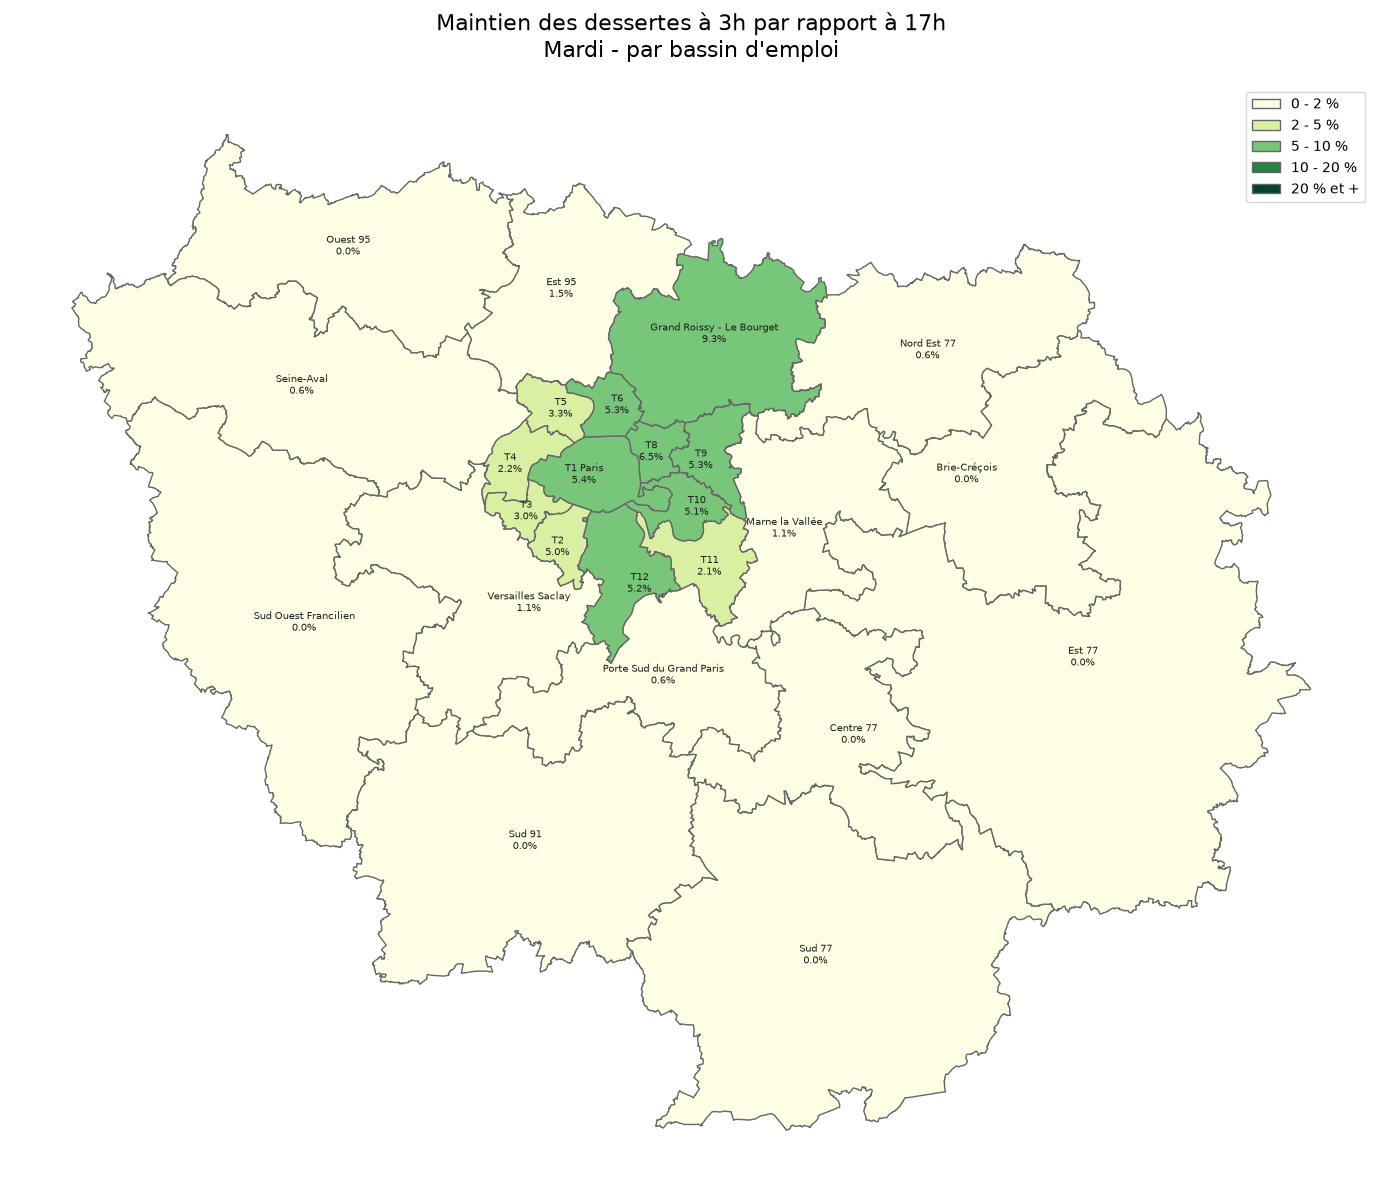

In [13]:
import matplotlib.pyplot as plt
import pandas as pd

# --------------------------------------------------
# 1. Créer des classes de taux
# --------------------------------------------------

bins = [-0.1, 2, 5, 10, 20, 100]
labels = [
    "0 - 2 %",
    "2 - 5 %",
    "5 - 10 %",
    "10 - 20 %",
    "20 % et +"
]

carte_bassins["classe_maintien"] = pd.cut(
    carte_bassins["taux_maintien_dessertes_pct"],
    bins=bins,
    labels=labels
)


# --------------------------------------------------
# 2. Carte
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(15, 12))

carte_bassins.plot(
    column="classe_maintien",
    categorical=True,
    cmap="YlGn",
    linewidth=1,
    edgecolor="#666666",
    legend=True,
    ax=ax,
    missing_kwds={
        "color": "#eeeeee",
        "label": "Pas de données"
    }
)


# --------------------------------------------------
# 3. Ajouter les noms + taux
# --------------------------------------------------

for _, bassin in carte_bassins.iterrows():

    point = bassin.geometry.representative_point()

    taux = bassin["taux_maintien_dessertes_pct"]

    if pd.notna(taux):
        texte = f"{bassin['NOM']}\n{taux:.1f}%"
    else:
        texte = str(bassin["NOM"])

    ax.annotate(
        texte,
        xy=(point.x, point.y),
        ha="center",
        va="center",
        fontsize=7,
        color="#222222"
    )


# --------------------------------------------------
# 4. Mise en forme
# --------------------------------------------------

ax.set_title(
    "Maintien des dessertes à 3h par rapport à 17h\nMardi - par bassin d'emploi",
    fontsize=16,
    pad=20
)

ax.axis("off")

plt.tight_layout()
plt.show() 

##### Bassin arrêt

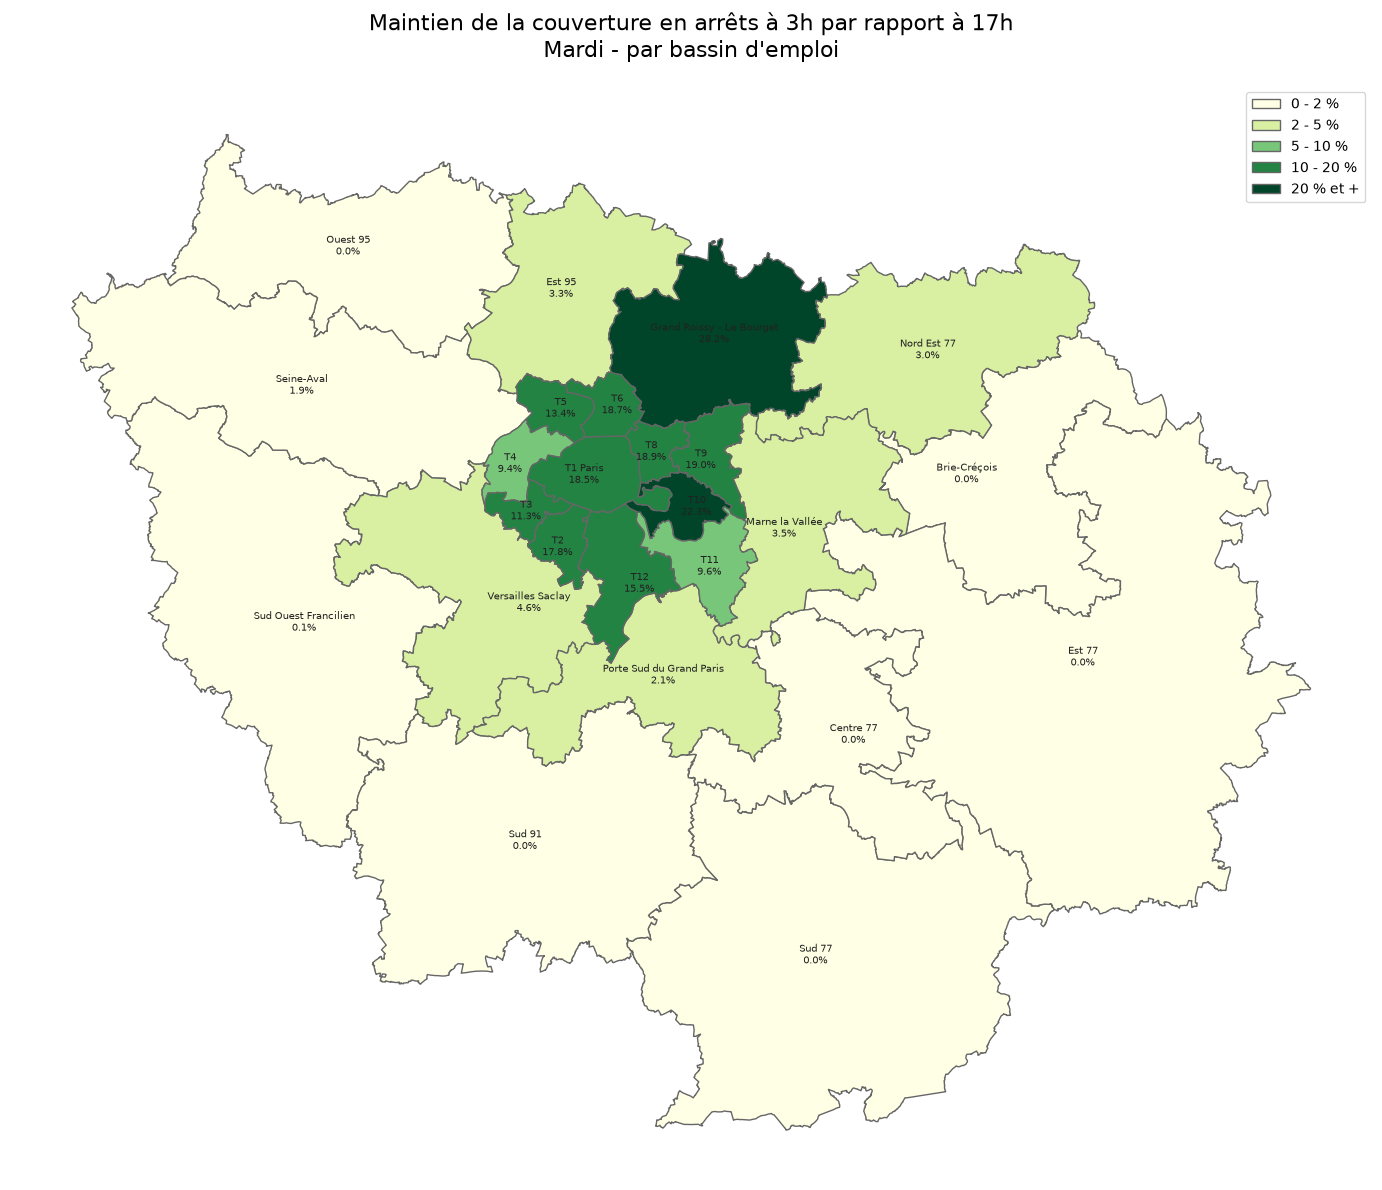

In [14]:

# --------------------------------------------------
# 1. Rattacher le taux de maintien des arrêts
#    aux polygones des bassins
# --------------------------------------------------

carte_bassins_arrets = df_bassin_geo.merge(
    comparaison_bassins[
        [
            "CODE_BE",
            "taux_maintien_3h_pct"
        ]
    ],
    on="CODE_BE",
    how="left"
)


# --------------------------------------------------
# 2. Créer les classes
# --------------------------------------------------

bins = [-0.1, 2, 5, 10, 20, 100]

labels = [
    "0 - 2 %",
    "2 - 5 %",
    "5 - 10 %",
    "10 - 20 %",
    "20 % et +"
]

carte_bassins_arrets["classe_maintien"] = pd.cut(
    carte_bassins_arrets["taux_maintien_3h_pct"],
    bins=bins,
    labels=labels
)


# --------------------------------------------------
# 3. Créer la carte
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(15, 12))

carte_bassins_arrets.plot(
    column="classe_maintien",
    categorical=True,
    cmap="YlGn",
    linewidth=1,
    edgecolor="#666666",
    legend=True,
    ax=ax,
    missing_kwds={
        "color": "#eeeeee",
        "label": "Pas de données"
    }
)


# --------------------------------------------------
# 4. Ajouter le nom du bassin + taux
# --------------------------------------------------

for _, bassin in carte_bassins_arrets.iterrows():

    point = bassin.geometry.representative_point()

    taux = bassin["taux_maintien_3h_pct"]

    if pd.notna(taux):
        texte = f"{bassin['NOM']}\n{taux:.1f}%"
    else:
        texte = str(bassin["NOM"])

    ax.annotate(
        texte,
        xy=(point.x, point.y),
        ha="center",
        va="center",
        fontsize=7,
        color="#222222"
    )


# --------------------------------------------------
# 5. Mise en forme
# --------------------------------------------------

ax.set_title(
    "Maintien de la couverture en arrêts à 3h par rapport à 17h\nMardi - par bassin d'emploi",
    fontsize=16,
    pad=20
)

ax.axis("off")

plt.tight_layout()
plt.show()